In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

Task 1, food delivery DataFrame (20 rows, 5 columns) and correlation matrix

In [2]:
n = 20
delivery_distance = rng.uniform(1, 12, n).round(1)
delivery_time = (15 + delivery_distance * 2.5 + rng.normal(0, 4, n)).round(1)
order_value = rng.uniform(150, 900, n).round(0)
tip_amount = (order_value * 0.05 + rng.normal(0, 8, n)).clip(0).round(0)
rating = (5 - delivery_time * 0.04 + rng.normal(0, 0.3, n)).clip(1, 5).round(1)

delivery = pd.DataFrame({
    'delivery_time': delivery_time,
    'order_value': order_value,
    'tip_amount': tip_amount,
    'rating': rating,
    'delivery_distance': delivery_distance,
})
print(delivery.head())

corr = delivery.corr()
corr

   delivery_time  order_value  tip_amount  rating  delivery_distance
0           38.0        478.0        17.0     3.7                9.5
1           26.8        775.0        46.0     3.8                5.8
2           45.9        675.0        20.0     3.3               10.4
3           36.1        384.0        17.0     3.4                8.7
4           18.3        774.0        40.0     4.2                2.0


,delivery_time,order_value,tip_amount,rating,delivery_distance
delivery_time,1.000000,-0.385087,-0.485563,-0.753603,0.919368
order_value,-0.385087,1.000000,0.839306,0.436267,-0.326846
tip_amount,-0.485563,0.839306,1.000000,0.392964,-0.461162
rating,-0.753603,0.436267,0.392964,1.000000,-0.744035
delivery_distance,0.919368,-0.326846,-0.461162,-0.744035,1.000000


Task 2, annotated heatmap

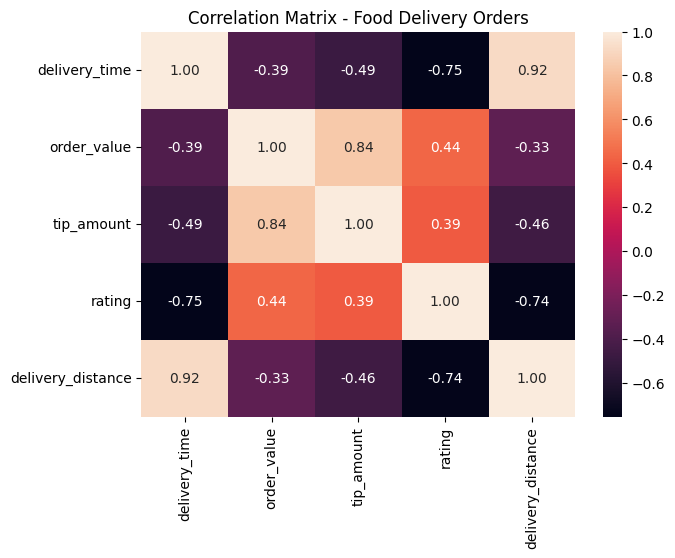

In [3]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f')
plt.title('Correlation Matrix - Food Delivery Orders')
plt.show()

Task 3, diverging palette and strongest negative pair

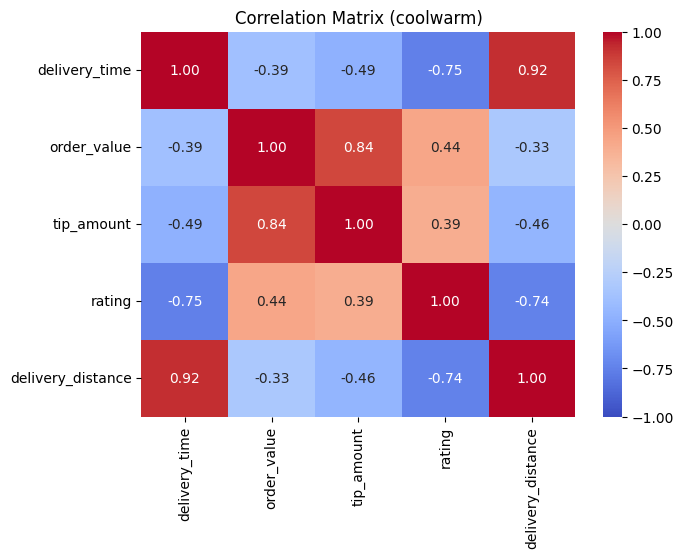

Strongest negative correlation: ('delivery_time', 'rating') -0.75


In [4]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlation Matrix (coolwarm)')
plt.show()

pairs = corr.where(~np.eye(len(corr), dtype=bool)).stack()
print('Strongest negative correlation:', pairs.idxmin(), round(pairs.min(), 2))

Task 4, Flipkart mobiles heatmap from a CSV

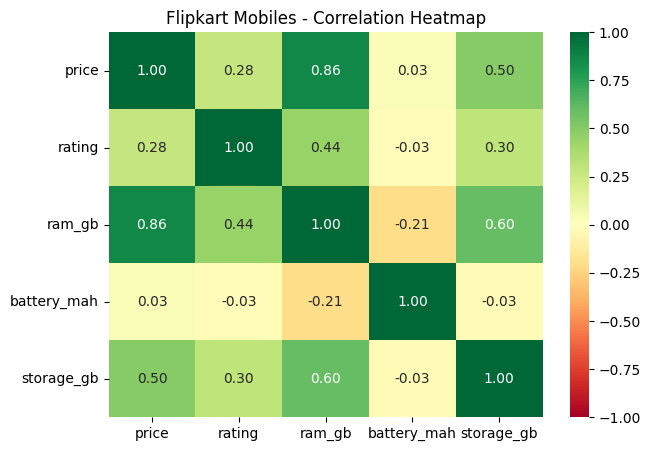

In [5]:
# Sample CSV (replace with your real Flipkart mobiles CSV if you have one)
m = 60
ram = rng.choice([2, 3, 4, 6, 8, 12], m)
battery = rng.choice([3000, 4000, 4500, 5000, 6000], m)
price = (ram * 1800 + battery * 1.5 + rng.normal(0, 3000, m)).clip(5000).round(0)
rating = (3.4 + ram * 0.05 + rng.normal(0, 0.3, m)).clip(1, 5).round(1)
storage = np.where(ram >= 6, 128, rng.choice([32, 64, 128], m))
pd.DataFrame({'price': price, 'rating': rating, 'ram_gb': ram,
              'battery_mah': battery, 'storage_gb': storage}).to_csv('flipkart_mobiles.csv', index=False)

mobiles = pd.read_csv('flipkart_mobiles.csv')
mobile_corr = mobiles.select_dtypes('number').corr()

plt.figure(figsize=(7, 5))
sns.heatmap(mobile_corr, annot=True, fmt='.2f', cmap='RdYlGn', vmin=-1, vmax=1, center=0)
plt.title('Flipkart Mobiles - Correlation Heatmap')
plt.show()